# Mini proyecto 2 - Analisis de datos morfologicos de 161 muestras de mango
La idea de este proyecto es analizar las muestras morfologicas de 161 plantas de mango. Tome la tabla de un trabajo titulado "A genome-wide association study identified SNP markers and candidate genes associated with morphometric fruit quality traitsin mangoes".
La tabla contiene 14 caracteristicas (columnas) de la fruta distibuidas en una tabla de 161 filas (una para cada fruta).
El objetivo de este trabajo es, con los datos de la tabla, ver que tanto nos dicen los datos obtenidos sobre las frutas. Para ello se va a realizar mineria de datos (PCA, vectores carga, Biplot) y luego utilizar los datos para entrenar un MLP y random forest para que predigan las distintas subpobalaciones.

## 1 Carga y preprocesamiento de datos

Las columnas contienen las caracteristicas morfologicas de cada mango y entre esas caracteristicas tenemos:
1 Peso de la fruta(g)

2 largo de la fruta(mm)

3 Ancho de la fruta(mm)

4 Grosor de la fruta (mm)

5 Peso del carozo (g)

6 Largo del carozo(mm)

7 Ancho del carozo(mm)

8 Grosor del carozo

9 Peso de la semilla (g)

10 Largo de la semilla (mm)

11 Ancho de la semilla (mm)

12 Grosor de la semilla (mm)

13 Brix: cuantifican la concentración de sólidos solubles totales en el jugo del fruto

14 Pulp: Corresponde al rendimiento de la fruta en cuanto a material comestible


Tambien contiene una columna con el nombre de cada accesion y la subpoblacion. El nombre sera eliminado en cada dataframe y la subpoblacion en el dataframe que va a ser utilizado para clustering.
Se encontraron valores faltantes en la medicion de "Stone Length", asi que esas filas (8 en total) fueron eliminadas.

### Cargo los datos y elimino las columnas faltantes

In [18]:
import pandas as pd
#Cargo el archivo excel con los datos y preparo mis df para los distintos objetivos planteados
# df1 para clustering y mineria, df2 para mlp y random forest
df_original = pd.read_excel('Supplementary Tables.xlsx', sheet_name=0, header=2, nrows=161)
#Elimino valores nulos
df_limpio = df_original.dropna().copy().reset_index(drop=True)
df_limpio['Subpopulation'] = df_limpio['Subpopulation'].astype(str).str.strip()
df1 = df_limpio.drop(columns=['Accession ID', 'Subpopulation'])
df2 = df_limpio.drop(columns=['Accession ID'])
df_original.to_csv('datos_limpios.txt', index=False)
print("Archivo guardado")


Archivo guardado


In [17]:
df1.head()


,fruitWeight (g),fruitLength (mm),fruitWidth (mm),fruitThickness (mm),stoneWeight (g),stoneLength (mm),stoneWidth (mm),stoneThickness (mm),seedWeight (g),seedLength (mm),seedWidth (mm),seedThickness (mm),brix,Pulp
0,143.902500,92.086667,62.600000,55.100000,26.233333,62.791667,38.533333,20.608333,16.941667,35.675000,28.416667,17.483333,5.485483,20.066667
1,236.141667,63.380000,83.005833,70.380000,20.641667,52.309167,42.194167,17.320833,12.320000,36.689167,25.055833,11.760833,11.440048,21.225000
2,153.836667,77.709167,57.760000,53.814167,13.435833,49.723333,27.686667,15.515000,8.490000,37.635000,18.021667,17.359167,11.449730,19.875000
3,135.718750,61.881250,64.485417,56.320000,15.834583,39.615000,38.090417,17.999583,9.800833,38.248333,25.460000,14.973750,8.571034,16.179167
4,240.704722,75.131111,72.321111,63.677778,28.556111,52.833889,38.603889,20.059167,14.240000,39.855278,25.588056,14.647222,8.429184,12.783333


In [13]:
df1.tail()

,fruitWeight (g),fruitLength (mm),fruitWidth (mm),fruitThickness (mm),stoneWeight (g),stoneLength (mm),stoneWidth (mm),stoneThickness (mm),seedWeight (g),seedLength (mm),seedWidth (mm),seedThickness (mm),brix,Pulp
147,537.666667,145.083333,93.250000,80.583333,55.958333,124.017500,53.973333,21.133333,26.975000,71.450833,36.264167,16.593333,9.608340,9.925000
148,463.491667,159.333333,79.409167,64.223333,31.241667,132.780833,35.145000,19.520833,18.575000,72.008333,28.565000,16.491667,14.835690,19.883333
149,298.450000,117.598333,71.517917,63.704167,38.779583,96.726250,34.159167,21.201667,25.233750,74.015833,25.625417,17.874167,7.696060,16.312500
150,492.091667,134.586667,83.125000,80.128333,49.977917,109.989167,39.722917,20.696250,28.172083,77.942083,33.267917,15.888750,9.846182,16.070833
151,931.329167,189.681250,103.295833,93.965833,54.415417,156.168750,48.405417,19.849167,32.418333,78.081250,38.994167,16.102500,17.115171,17.387500


In [15]:
df2.head()

,Subpopulation,fruitWeight (g),fruitLength (mm),fruitWidth (mm),fruitThickness (mm),stoneWeight (g),stoneLength (mm),stoneWidth (mm),stoneThickness (mm),seedWeight (g),seedLength (mm),seedWidth (mm),seedThickness (mm),brix,Pulp
0,SP2,143.902500,92.086667,62.600000,55.100000,26.233333,62.791667,38.533333,20.608333,16.941667,35.675000,28.416667,17.483333,5.485483,20.066667
1,SP2,236.141667,63.380000,83.005833,70.380000,20.641667,52.309167,42.194167,17.320833,12.320000,36.689167,25.055833,11.760833,11.440048,21.225000
2,SP2,153.836667,77.709167,57.760000,53.814167,13.435833,49.723333,27.686667,15.515000,8.490000,37.635000,18.021667,17.359167,11.449730,19.875000
3,SP2,135.718750,61.881250,64.485417,56.320000,15.834583,39.615000,38.090417,17.999583,9.800833,38.248333,25.460000,14.973750,8.571034,16.179167
4,SP2,240.704722,75.131111,72.321111,63.677778,28.556111,52.833889,38.603889,20.059167,14.240000,39.855278,25.588056,14.647222,8.429184,12.783333


In [16]:

df2.tail()

,Subpopulation,fruitWeight (g),fruitLength (mm),fruitWidth (mm),fruitThickness (mm),stoneWeight (g),stoneLength (mm),stoneWidth (mm),stoneThickness (mm),seedWeight (g),seedLength (mm),seedWidth (mm),seedThickness (mm),brix,Pulp
147,SP1,537.666667,145.083333,93.250000,80.583333,55.958333,124.017500,53.973333,21.133333,26.975000,71.450833,36.264167,16.593333,9.608340,9.925000
148,SP1,463.491667,159.333333,79.409167,64.223333,31.241667,132.780833,35.145000,19.520833,18.575000,72.008333,28.565000,16.491667,14.835690,19.883333
149,SP1,298.450000,117.598333,71.517917,63.704167,38.779583,96.726250,34.159167,21.201667,25.233750,74.015833,25.625417,17.874167,7.696060,16.312500
150,SP1,492.091667,134.586667,83.125000,80.128333,49.977917,109.989167,39.722917,20.696250,28.172083,77.942083,33.267917,15.888750,9.846182,16.070833
151,SP1,931.329167,189.681250,103.295833,93.965833,54.415417,156.168750,48.405417,19.849167,32.418333,78.081250,38.994167,16.102500,17.115171,17.387500


En ambos dataframe se eliminaron los valores faltantes y en cada uno en particular sus columnas correspondientes

### Normalizo y aplico label encoder

In [33]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

#Cambio las etiquetas de subpoblacion a valores numericos
label_encoder = LabelEncoder()
y_etiquetas = label_encoder.fit_transform(df2['Subpopulation'])
#Normalizo los datos
scaler = MinMaxScaler()
df1_norm = scaler.fit_transform(df1)
# Convertirlo a un DataFrame para mejor visualización
df1_norm_df = pd.DataFrame(df1_norm, columns=df1.columns)
summary = df1_norm_df.describe()
print(summary)

       fruitWeight (g)  fruitLength (mm)  fruitWidth (mm)  \
count       152.000000        152.000000       152.000000   
mean          0.329165          0.340126         0.488518   
std           0.171990          0.167500         0.184242   
min           0.000000          0.000000         0.000000   
25%           0.213897          0.233790         0.364924   
50%           0.310610          0.328416         0.488128   
75%           0.432128          0.426359         0.618346   
max           1.000000          1.000000         1.000000   

       fruitThickness (mm)  stoneWeight (g)  stoneLength (mm)  \
count           152.000000       152.000000        152.000000   
mean              0.558463         0.411491          0.363859   
std               0.186053         0.190750          0.171008   
min               0.000000         0.000000          0.000000   
25%               0.432066         0.286386          0.239357   
50%               0.551476         0.394574          0.35133

## 2 Mineria de datos
Con los datos ya pre procesados podemos comenzar con PCA, vextores y biplot

### PCA

In [23]:
from sklearn.decomposition import PCA
# Le aplico el PCA
pca = PCA()
X_pca = pca.fit_transform(df1_norm)


In [29]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import pandas as pd


pca = PCA()
X_pca = pca.fit_transform(df1_norm)

### Visualizo los datos

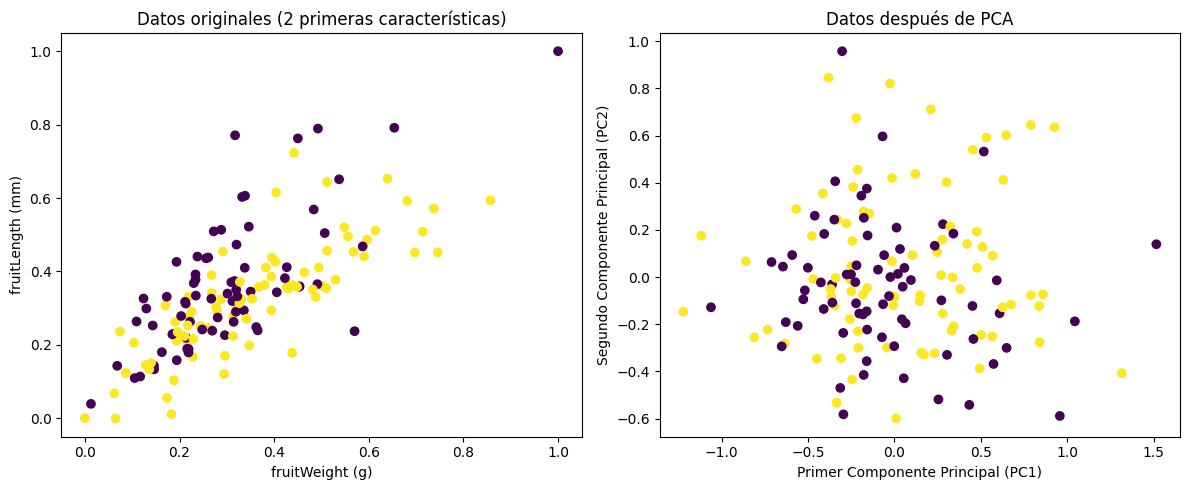

In [25]:
import matplotlib.pyplot as plt
# Visualizar los datos originales (usando solo las dos primeras características)
plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.scatter(df1_norm[:, 0], df1_norm[:, 1], c=y_etiquetas, cmap='viridis')
plt.title("Datos originales (2 primeras características)")
plt.xlabel(df1.columns[0])
plt.ylabel(df1.columns[1])

# Visualizar los datos después de aplicar PCA
plt.subplot(122)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_etiquetas, cmap='viridis')
plt.title("Datos después de PCA")
plt.xlabel("Primer Componente Principal (PC1)")
plt.ylabel("Segundo Componente Principal (PC2)")

plt.tight_layout()

Al aplicar la normalizacion evitamos que ciertos atributos que tienen distinta unidad de medida abarquen todo el analisis por ser mas grandes (el peso es un numero mayor al de grados brix por ejemplo). Cuando graficamos las PCA 1 y PCA 2, vemos que hay un solapamiento entre las 2 subpoblaciones que detecta. Esto nos dice que no hay  separabilidad lineal simple entre ambos grupos. Si bien podemos ver que podemos reducir la dimensionalidad, no es suficiente y se deben probar otros metodos de analisis.

In [34]:
# Obtener los vectores de carga (loadings)
loadings = pca.components_.T

# Crear un DataFrame con los loadings
loadings_df = pd.DataFrame(loadings, columns=[f'PC{i}' for i in range(1, len(loadings[0]) + 1)],
                           index=df1.columns)

# Imprimir los loadings
print("Vectores de carga (Loadings):")
print(loadings_df)

print("Vectores de carga (Loadings):")
print(loadings_df)
print("\n")

Vectores de carga (Loadings):
                          PC1       PC2       PC3       PC4       PC5  \
fruitWeight (g)      0.339141  0.164116  0.005526  0.075139 -0.143002   
fruitLength (mm)     0.242137  0.182744  0.439210 -0.072437 -0.091531   
fruitWidth (mm)      0.346015  0.139985 -0.259492  0.129931 -0.147488   
fruitThickness (mm)  0.338484  0.119684 -0.286238  0.088358 -0.224353   
stoneWeight (g)      0.322705 -0.294895  0.100486  0.061886  0.117038   
stoneLength (mm)     0.209760  0.178102  0.516447 -0.063529 -0.018776   
stoneWidth (mm)      0.331636  0.074432 -0.191096  0.237042  0.505546   
stoneThickness (mm)  0.144481 -0.384734 -0.168678  0.027230 -0.338214   
seedWeight (g)       0.302823 -0.358108  0.042426 -0.018376  0.028456   
seedLength (mm)      0.275155 -0.203512  0.424991 -0.254206 -0.012810   
seedWidth (mm)       0.264376 -0.098944 -0.102270  0.125313  0.464870   
seedThickness (mm)   0.099188 -0.393817 -0.128995 -0.071076 -0.410810   
brix                 

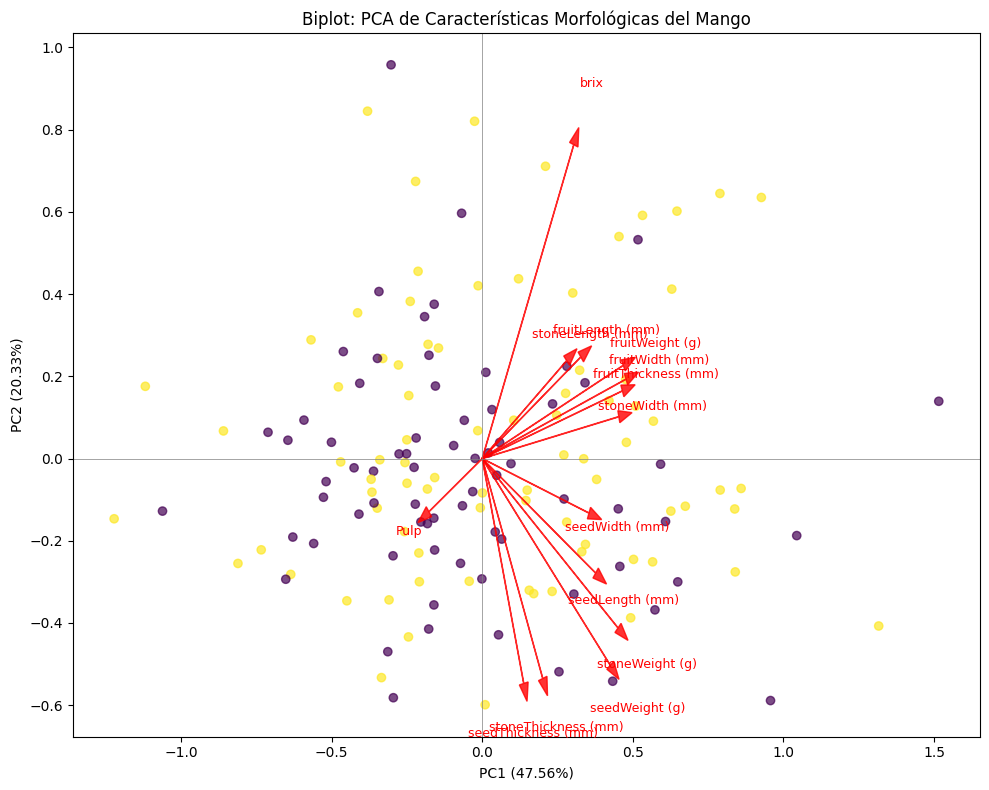

In [37]:
plt.figure(figsize=(10, 8))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_etiquetas, cmap='viridis', alpha=0.7)

# Dibujar los vectores de carga
for i, (lx, ly) in enumerate(zip(loadings[:, 0], loadings[:, 1])):
    plt.arrow(0, 0, lx * 1.5, ly * 1.5, color='r', alpha=0.8,
              head_width=0.03, length_includes_head=True)
    plt.text(lx * 1.7, ly * 1.7, df1.columns[i],
             color='r', ha='center', va='center', fontsize=9)

plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('Biplot: PCA de Características Morfológicas del Mango')
plt.tight_layout()
plt.show()

El análisis de la matriz de vectores de carga confirma numéricamente que el PC1 está dominado por las proporciones físicas y de tamaño del fruto, siendo fruitWidth (mm) (0.3460), fruitThickness (mm) (0.3384) y fruitWeight (g) (0.3391) las características más relevantes. Por su parte, el PC2 captura la calidad bioquímica, donde el contenido de azúcar o brix es la variable con mayor peso (0.5368). Como marcamos antes la proyección visual del biplot nos muestra que hay  un solapamiento grande entre las subpoblaciones SP1 y SP2. Esto nos muestra que ambos grupos comparten una estructura morfológica muy similar y no existe una frontera de separación lineal simple entre ellos.

## 3 Machine Learning_1 - Random forest vs Arbol de decision

### Random forest

In [58]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix


X_rf = df2.drop(columns=['Subpopulation'])
y_rf = y_etiquetas

# Verifico que todo siga en su lugar
print("Verificación de X (Features):", X_rf.shape)
print("Verificación de y (Clases):", y_rf.shape)

Verificación de X (Features): (152, 14)
Verificación de y (Clases): (152,)


In [41]:
rf_model = RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)
rf_model.fit(X_rf, y_rf)

RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)

In [42]:
# Imprimir un resumen del modelo
print("Resumen del modelo Random Forest:")
print(f"Número de árboles: {rf_model.n_estimators}")
print(f"Precisión OOB: {rf_model.oob_score_:.4f}")
print(f"Número de características: {rf_model.n_features_in_}")
print(f"Clases: {rf_model.classes_}")

Resumen del modelo Random Forest:
Número de árboles: 1000
Precisión OOB: 0.6579
Número de características: 14
Clases: [0 1]


In [43]:
# Importancia de las características
feature_importance = rf_model.feature_importances_
for i, importance in enumerate(feature_importance):
    print(f"Importancia de la característica {i+1}: {importance:.4f}")

Importancia de la característica 1: 0.0539
Importancia de la característica 2: 0.0596
Importancia de la característica 3: 0.0749
Importancia de la característica 4: 0.0703
Importancia de la característica 5: 0.0621
Importancia de la característica 6: 0.0910
Importancia de la característica 7: 0.0528
Importancia de la característica 8: 0.0456
Importancia de la característica 9: 0.0530
Importancia de la característica 10: 0.1104
Importancia de la característica 11: 0.0852
Importancia de la característica 12: 0.0583
Importancia de la característica 13: 0.0807
Importancia de la característica 14: 0.1021


In [45]:
# Obtener las predicciones OOB
oob_predictions = rf_model.oob_decision_function_

# Convertir probabilidades a etiquetas de clase (la clase con la probabilidad más alta)
oob_predicted_labels = rf_model.classes_[np.argmax(oob_predictions, axis=1)]

# Crear la matriz de confusión usando las etiquetas reales y las predicciones OOB
conf_matrix = confusion_matrix(y_rf, oob_predicted_labels, labels=rf_model.classes_)

# Convertir la matriz de confusión a un DataFrame para un formato legible
conf_matrix_df = pd.DataFrame(conf_matrix, index=rf_model.classes_, columns=rf_model.classes_)

# Calcular el error de clase para cada clase
class_error = 1 - np.diag(conf_matrix) / np.sum(conf_matrix, axis=1)

# Imprimir la matriz de confusión con nombres de filas y columnas
print("Matriz de Confusión OOB con Nombres de Clases:")
print(conf_matrix_df)

# Imprimir el error de clase para cada clase
print("\nError de Clase (Class Error) por clase:")
for cls, error in zip(rf_model.classes_, class_error):
    print(f"Clase {cls}: Error de Clase {error:.4f}")

Matriz de Confusión OOB con Nombres de Clases:
    0   1
0  42  29
1  23  58

Error de Clase (Class Error) por clase:
Clase 0: Error de Clase 0.4085
Clase 1: Error de Clase 0.2840


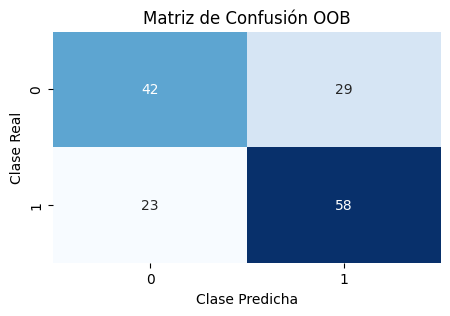

In [46]:
import seaborn as sns

# Visualizar la matriz de confusión usando un heatmap
plt.figure(figsize=(5, 3))
sns.heatmap(conf_matrix_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión OOB')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

El entrenamiento del modelo Random Forest se hizo con OOB, obteniendo una precisión general de 0.6579. Al ver la matriz de confusion, vemos que identifica mejor la  subpoblación SP2, logrando 58 aciertos frente a 23 errores (28.4% de error de clase), pero le costo mas clasificar correctamente a la subpoblación SP1 (clase 0), registrando 42 aciertos y 29 errores (40.85% de error). Al extraer la importancia de las características, el modelo determinó que la longitud de la semilla (seedLength (mm), 0.1104) y el contenido de pulpa (Pulp, 0.1021) son las variables más importantes para diferenciar ambos grupos, revelando relaciones no lineales que el PCA no habia detectado

¿Qué ventajas tiene la evaluación OOB?
La principal ventaja es que permite estimar el rendimiento y el error de generalización del modelo sin necesidad de sacrificar datos para crear un conjunto de validación separado. En datasets pequeños, como este de 152 muestras de mangos, extraer un 30% para testeo reduce severamente la información disponible para que el modelo aprenda. La evaluación OOB (Out-Of-Bag) permite utilizar el 100% del dataset para el entrenamiento general del bosque.

### Arbol de decision

In [48]:
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# dividir los datos en conjuntos de entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(X_rf, y_rf, test_size=0.3, random_state=0)


In [49]:
# Obtener las frecuencias de clases en el conjunto total de entrenamiento
clases_train = pd.Series(y_train).value_counts()
print(clases_train)
# Calcular el total de frecuencias
total_frecuencias = clases_train.sum()
print(f'Total {total_frecuencias}')

1    62
0    44
Name: count, dtype: int64
Total 106


In [50]:
# Obtener las frecuencias de clases en el conjunto total de test
clases_test = pd.Series(y_test).value_counts()
print(clases_test)
# Calcular el total de frecuencias
total_frecuencias = clases_test.sum()
print(f'Total {total_frecuencias}')

0    27
1    19
Name: count, dtype: int64
Total 46


In [51]:
# definir y entrenar el modelo
clf = DecisionTreeClassifier(criterion="entropy", min_impurity_decrease=0.03, random_state=0, min_samples_leaf=5)
clf.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.03,
                       min_samples_leaf=5, random_state=0)

In [52]:
# predecir las etiquetas para los datos de prueba y calcular la precisión del modelo
y_pred = clf.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)

# imprimir la precisión del modelo
print("Precisión del modelo: {:.2f}".format(accuracy))

Precisión del modelo: 0.65


In [53]:
# Imprimir información sobre el árbol
print(f'Profundidad del árbol: {clf.get_depth()}')
print(f'Número de hojas: {clf.get_n_leaves()}')

Profundidad del árbol: 7
Número de hojas: 10


In [55]:
# Imprimir las características más importantes ordenadas
importances = clf.feature_importances_
sorted_indices = np.argsort(importances)[::-1] # Ordena los índices en orden descendente

print('Variables más importantes ordenadas:')
for idx in sorted_indices:
    feature_name = X_rf.columns[idx]
    importance = importances[idx]
    print(f'{feature_name}: {importance}')

Variables más importantes ordenadas:
seedLength (mm): 0.2374930103426309
Pulp: 0.21494512391701573
stoneWidth (mm): 0.14971287476514994
stoneLength (mm): 0.12352357090088202
seedWidth (mm): 0.12130705378743359
stoneWeight (g): 0.08217598243101254
seedThickness (mm): 0.07084238385587523
brix: 0.0
seedWeight (g): 0.0
stoneThickness (mm): 0.0
fruitThickness (mm): 0.0
fruitWidth (mm): 0.0
fruitLength (mm): 0.0
fruitWeight (g): 0.0


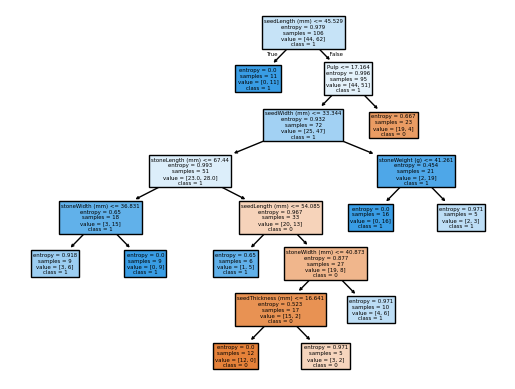

In [57]:
plot_tree(clf, filled=True, feature_names=X_rf.columns[0:29], class_names=[str(cls) for cls in clf.classes_])
plt.savefig('decision_tree.pdf', format='pdf')  # Guarda el árbol en formato PDF
plt.show()  # Muestra el árbol en pantalla

Para implementar del arbol de decisión, la validación se realizó dividiendo el conjunto de datos en un 70% para entrenamiento y un 30% para prueba, logrando una precisión del 65% sobre las muestras independientes. El modelo estructuró un árbol con una profundidad máxima de 7 niveles y un total de 10 hojas. La evaluación de importancia de variablesn nos muestra lo mismo que el random forest, que seedLength (mm) (0.237) y Pulp (0.215) fueron los descriptores más relevantes.

###.

Tanto el modelo de ensamble (Random Forest) como el modelo simple (Árbol de Decisión) lograron una precisión predictiva casi idéntica (65.79% en OOB vs 65.00% en Test). Tambien es interesante que ambos algoritmos descubrieron que las variables que mejor separan a las subpoblaciones SP1 y SP2 no son las de volumen general que dominaban el PCA (como el ancho o peso del fruto), sino las dimensiones específicas de la semilla y la calidad de la pulpa. El árbol de decisión confirmó gráficamente esta regla de clasificación, demostrando que la morfología interna del fruto es el factor determinante para diferenciar estas variedades genéticas

## 4 Machine Learning_2 - MLP/Deep Learning

In [61]:
from sklearn.model_selection import train_test_split

# Separar datos para entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X_rf, y_rf, train_size=0.8, test_size=0.2, random_state=42)

# Subdividir el conjunto de entrenamiento en train y val
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, train_size=0.8, test_size=0.2, random_state=42)

print("Tamaño del conjunto de entrenamiento:", len(X_train))
print("Tamaño del conjunto de validación:", len(X_val))
print("Tamaño del conjunto de prueba:", len(X_test))

Tamaño del conjunto de entrenamiento: 96
Tamaño del conjunto de validación: 25
Tamaño del conjunto de prueba: 31


In [66]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Definir la red neuronal
model = models.Sequential()
model.add(layers.Dropout(0.5))
model.add(layers.Dense(128, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dense(8, activation='softmax'))  # Cambiar

In [67]:
# Compilar el modelo
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

In [68]:
# Definir hiperparámetros
epocas = 20
batch_size = 32

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.3229 - loss: 1.9973 - val_accuracy: 0.6000 - val_loss: 1.6525
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.3542 - loss: 1.8075 - val_accuracy: 0.6400 - val_loss: 1.6221
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.3333 - loss: 1.8960 - val_accuracy: 0.6000 - val_loss: 1.5918
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3229 - loss: 1.7970 - val_accuracy: 0.6400 - val_loss: 1.5612
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.3750 - loss: 1.7636 - val_accuracy: 0.6400 - val_loss: 1.5419
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.4062 - loss: 1.6846 - val_accuracy: 0.6400 - val_loss: 1.5351
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3438 - loss: 1.9286 - val_accuracy: 0.6000 - val_loss: 1.5283
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.4167 - loss: 1.7504 - val_accuracy: 0.5200 - val_loss: 1.5244

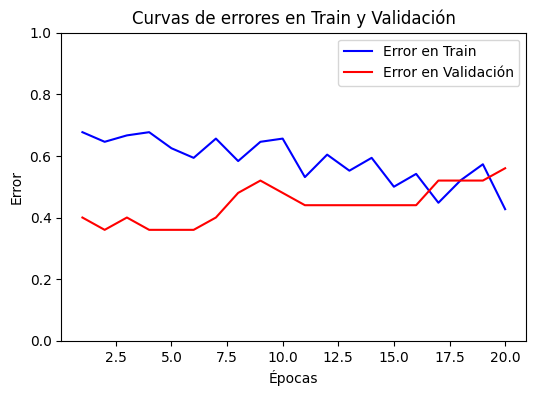

Precisión del modelo MLP en Test: 0.6129
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


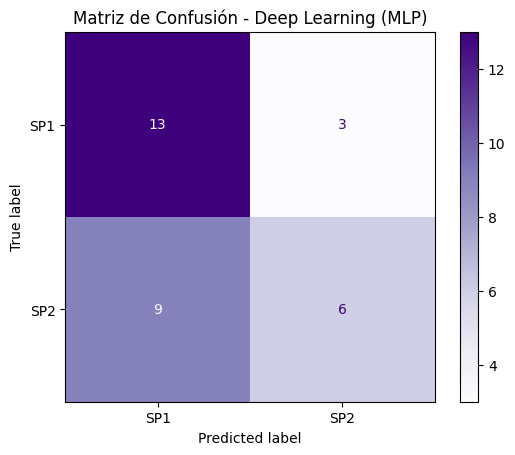

In [70]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

#  Entrenar el modelo y almacenar el historial
history = model.fit(X_train, y_train, epochs=epocas, batch_size=batch_size, validation_data=(X_val, y_val))

#  Graficar error en función de las épocas
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

Error_train = [1 - acc for acc in train_accuracy]
Error_val = [1 - acc for acc in val_accuracy]

epochs = range(1, len(train_accuracy) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, Error_train, 'b', label='Error en Train')
plt.plot(epochs, Error_val, 'r', label='Error en Validación')
plt.title('Curvas de errores en Train y Validación')
plt.xlabel('Épocas')
plt.ylabel('Error')
plt.ylim([0, 1])
plt.legend()
plt.show()

#  Evaluar el modelo de Keras en el conjunto de prueba
loss_test, accuracy_test = model.evaluate(X_test, y_test, verbose=0)
print(f"Precisión del modelo MLP en Test: {accuracy_test:.4f}")

#  Obtener las predicciones y generar la matriz de confusión
y_pred_prob = model.predict(X_test)
y_pred_mlp = np.argmax(y_pred_prob, axis=1)
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

# Mostrar la matriz de confusión utilizando label_encoder
disp_mlp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=label_encoder.classes_)
disp_mlp.plot(cmap='Purples')
plt.title("Matriz de Confusión - Deep Learning (MLP)")
plt.show()

La implementación del Perceptrón Multicapa (MLP) arrojó una precisión final en el conjunto de prueba de 0.6129 (61.29%). Mientras el error sobre los datos de entrenamiento (linea azul) desciende de manera constante hasta estabilizarse cerca de 0.4, el error de validación (línea roja) cambia mucho y se queda por encima de 0.4. Esto puede ser asi por el overfitting, ya que hay pocas muestras. La matriz de confusión refleja que el algoritmo tiene un sesgo hacia la clase SP1, pero le cuesta generalizar los patrones de la clase SP2, donde clasificó erróneamente 9 muestras como si fueran SP1 y solo logró 6 predicciones correctas

## Conclusiones
El análisis  de las 161 accesiones de mango demostró que las subpoblaciones SP1 y SP2 comparten una alta similitud morfológica general a nivel lineal. La reducción de dimensionalidad mediante PCA nos mostro que el volumen físico del fruto (PC1) y su calidad bioquímica (PC2) dominan la distribución de los datos, pero resultan insuficientes para trazar una frontera de clasificación simple debido al solapamiento natural de los grupos
Al comparar las tres metodologías de Machine Learning implementadas, los algoritmos de arbol de decision y random forest demostraron ser significativamente más efectivos y estables que la red neuronal. Aunque el MLP alcanzó un 61.29% de precisión, sufre mucho el dataset chico (152 muestras), tanto el Random Forest (65.79% en evaluación OOB) como el arbol de decisión (65.0% en test) lograron un desempeño predictivo superior.
Un encuentro interesante es que los algoritmos de decision coincidieron en discriminar a las frutas por el tamaño de sus semillas y el rendimiento de la pulpa y no por su morfologia externa.
En el estudio original, la separcion por poblaciones estuvo dada por diferencias en marcadores geneticos y no por las caracteristicas morfologicas. Si bien no se llego a la precision del estudio original, fue posible realizar un analisis de los datos morfologicos para poder separar poblaciones de mango.